#  Crop Recommendation System - Exploratory Data Analysis (EDA)
---
### Objective:
Perform detailed EDA on the **Crop Recommendation Dataset** to understand the distribution, correlation, and relationships between soil nutrients, climate conditions, and recommended crops.


In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
%matplotlib inline

In [2]:
# Load dataset
data = pd.read_csv('../data/Crop_recommendation.csv')
data.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
# Basic info
print('Shape of dataset:', data.shape)
print('Data types:')
print(data.dtypes)
print('Missing values:')
print(data.isnull().sum())

Shape of dataset: (2200, 8)
Data types:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object
Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [4]:
# Statistical summary
data.describe().T

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


##  Step 1: Univariate Analysis

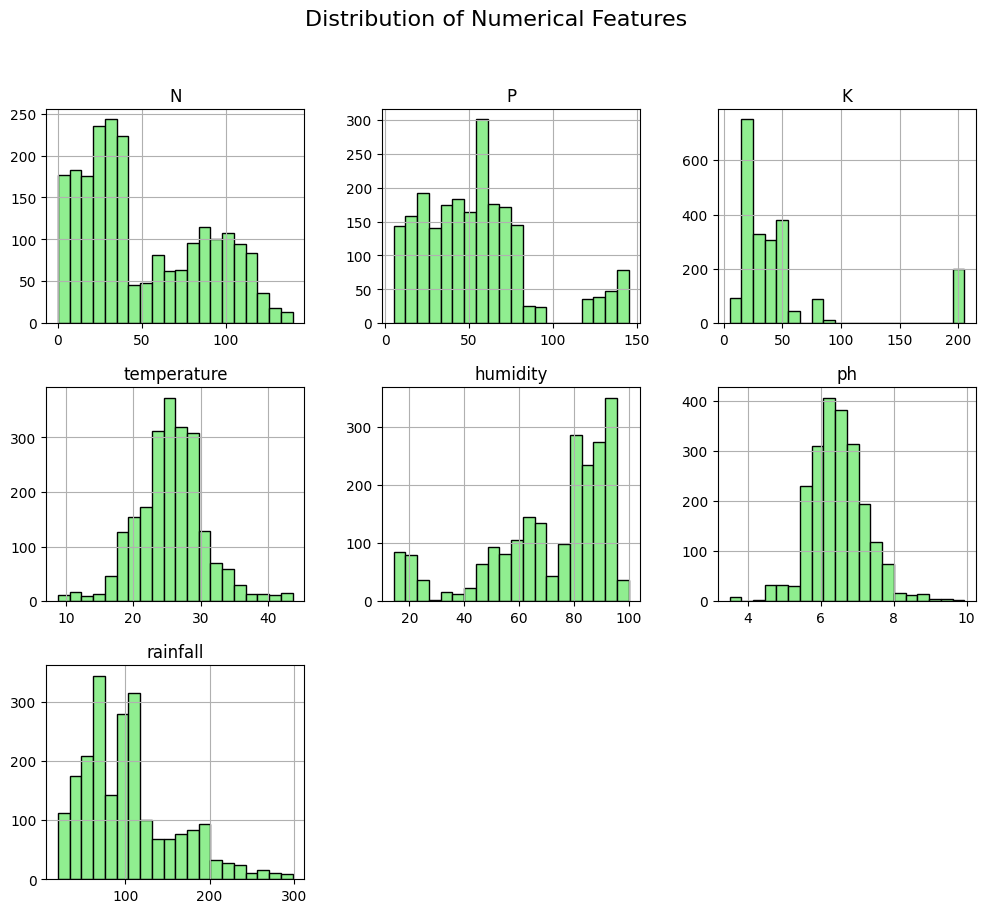

In [5]:
# Numerical columns distribution
num_cols = data.select_dtypes(include=['int64', 'float64']).columns
data[num_cols].hist(bins=20, figsize=(12,10), color='lightgreen', edgecolor='black')
plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.show()

C:\Users\Kirti\AppData\Local\Temp\ipykernel_5108\3628678092.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='label', data=data, order=data['label'].value_counts().index, palette='viridis')


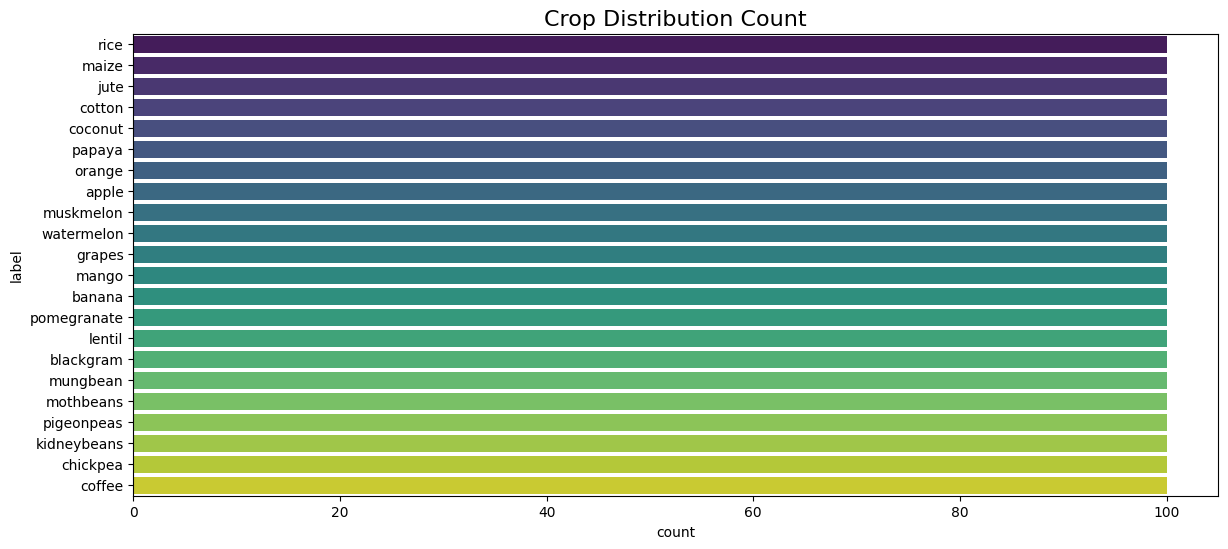

In [6]:
# Crop count
plt.figure(figsize=(14,6))
sns.countplot(y='label', data=data, order=data['label'].value_counts().index, palette='viridis')
plt.title('Crop Distribution Count', fontsize=16)
plt.show()

##  Step 2: Bivariate Analysis

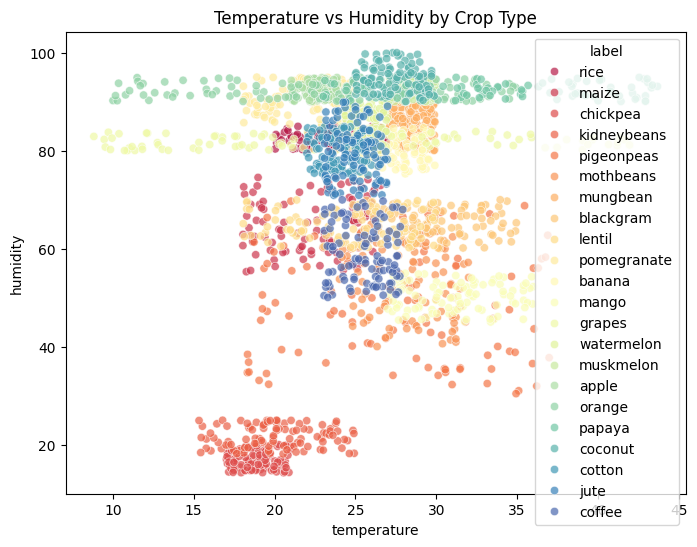

In [7]:
# Temperature vs Humidity
plt.figure(figsize=(8,6))
sns.scatterplot(x='temperature', y='humidity', hue='label', data=data, palette='Spectral', alpha=0.7)
plt.title('Temperature vs Humidity by Crop Type')
plt.show()

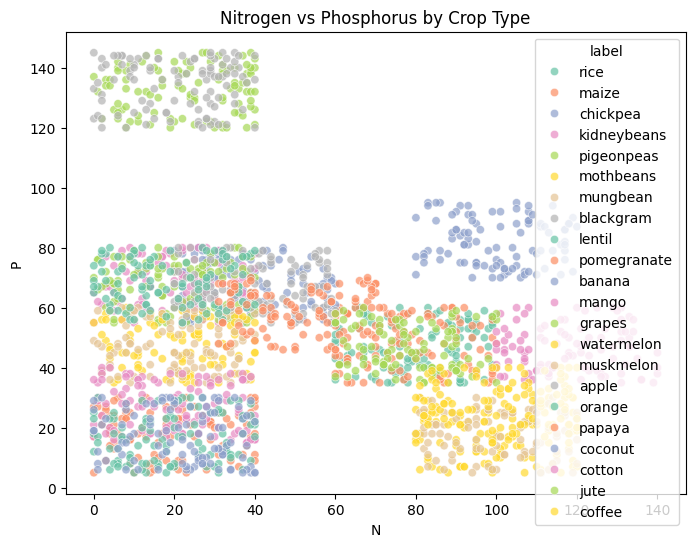

In [8]:
# Nitrogen vs Phosphorus
plt.figure(figsize=(8,6))
sns.scatterplot(x='N', y='P', hue='label', data=data, palette='Set2', alpha=0.7)
plt.title('Nitrogen vs Phosphorus by Crop Type')
plt.show()

## Step 3: Correlation Analysis

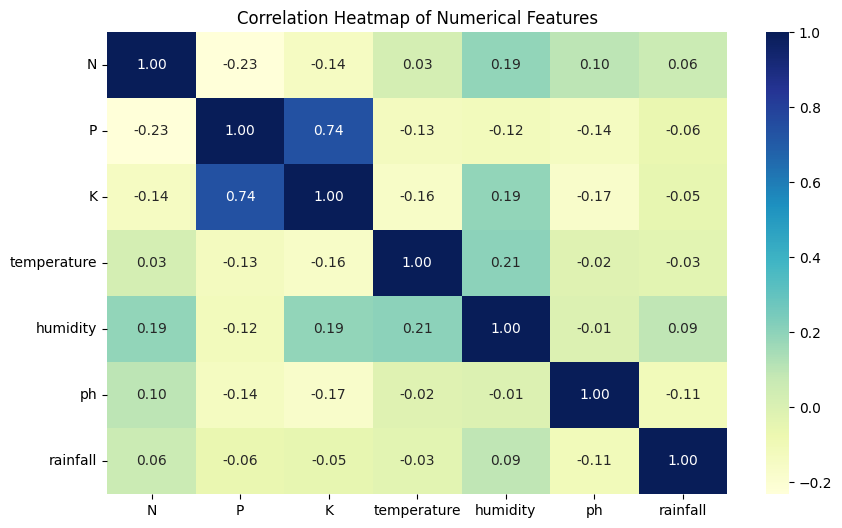

In [9]:
corr = data.corr(numeric_only=True)
plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='YlGnBu', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

## Step 4: Insights Summary
- Crops like **rice, maize, and cotton** require high nitrogen content.
- **Temperature** and **humidity** play a significant role in distinguishing crop suitability.
- **Soil pH** and **rainfall** influence crops like lentil, chickpea, and wheat.
- Dataset is **balanced** across crops.
- No missing values — clean dataset ready for preprocessing.